<a href="https://colab.research.google.com/github/sandy261094/deep-learning-journey/blob/main/Transfer_Learning_Tensorflow_Feature_Extraction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!nvidia-smi

Thu Oct 29 19:38:53 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   49C    P8             12W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

### Download and become one with the data

In [ ]:
import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"

In [ ]:
import zipfile
!wget https://storage.googleapis.com/ztm_tf_course/food_vision/10_food_classes_10_percent.zip
zip_ref = zipfile.ZipFile("10_food_classes_10_percent.zip")
zip_ref.extractall()
zip_ref.close()


--2026-10-29 19:38:53--  https://storage.googleapis.com/ztm_tf_course/food_vision/10_food_classes_10_percent.zip
Resolving storage.googleapis.com (storage.googleapis.com)... 74.125.200.207, 74.125.130.207, 74.125.68.207, ...
Connecting to storage.googleapis.com (storage.googleapis.com)|74.125.200.207|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 168546183 (161M) [application/zip]
Saving to: ‘10_food_classes_10_percent.zip’

10_food_classes_10_ 100%[===================>] 160.74M  17.4MB/s    in 10s     

2026-10-29 19:39:04 (15.3 MB/s) - ‘10_food_classes_10_percent.zip’ saved [168546183/168546183]



In [ ]:
import os
for dirnames, dirpath, filenames in os.walk("10_food_classes_10_percent"):
  print(f"There are {len(dirpath)} directories and {len(filenames)} images in {dirnames}")

There are 2 directories and 0 images in 10_food_classes_10_percent
There are 10 directories and 0 images in 10_food_classes_10_percent/test
There are 0 directories and 250 images in 10_food_classes_10_percent/test/ramen
There are 0 directories and 250 images in 10_food_classes_10_percent/test/ice_cream
There are 0 directories and 250 images in 10_food_classes_10_percent/test/grilled_salmon
There are 0 directories and 250 images in 10_food_classes_10_percent/test/pizza
There are 0 directories and 250 images in 10_food_classes_10_percent/test/hamburger
There are 0 directories and 250 images in 10_food_classes_10_percent/test/fried_rice
There are 0 directories and 250 images in 10_food_classes_10_percent/test/chicken_curry
There are 0 directories and 250 images in 10_food_classes_10_percent/test/chicken_wings
There are 0 directories and 250 images in 10_food_classes_10_percent/test/steak
There are 0 directories and 250 images in 10_food_classes_10_percent/test/sushi
There are 10 directori

In [ ]:
import pathlib
import numpy as np
data_dir = pathlib.Path("10_food_classes_10_percent/train/") # turn our training path into a Python path
class_names = np.array(sorted([item.name for item in data_dir.glob('*')])) # created a list of class_names from the subdirectories
print(class_names)

['chicken_curry' 'chicken_wings' 'fried_rice' 'grilled_salmon' 'hamburger'
 'ice_cream' 'pizza' 'ramen' 'steak' 'sushi']


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
IMAGE_SHAPE = (224,224)
BATCH_SIZE = 32

train_dir = "10_food_classes_10_percent/train"
test_dir = "10_food_classes_10_percent/test"

train_datagen = ImageDataGenerator(rescale=1/255.)
test_datagen = ImageDataGenerator(rescale=1/255.)

print("Training Images:")
train_data_10_percent = train_datagen.flow_from_directory(train_dir,
                                                          target_size=IMAGE_SHAPE,
                                                          batch_size=BATCH_SIZE,
                                                          class_mode="categorical")

print("Testing Images:")
test_data = test_datagen.flow_from_directory(test_dir,
                                             target_size=IMAGE_SHAPE,
                                             batch_size=BATCH_SIZE,
                                             class_mode="categorical")


Training Images:
Found 750 images belonging to 10 classes.
Testing Images:
Found 2500 images belonging to 10 classes.


### Setting up callbacks

Callbacks are extra functionality you can add to your models to be performed during or after training. Some of the most popular callbacks are:
1. Tracking experiments with tensorboard
2. Model checkpointing with model checkpoint callbacks
3. Stopping a model from training ( before it trains too long and overfits) with the EarlyStopping callback

In [ ]:
# Create tensorboard callback ( fiunctionized because everytime we need to create a new for each model)
import datetime
import tensorflow as tf

def create_tensorboard_callback(dir_name, experiment_name):
  log_dir = dir_name + "/" + experiment_name + "/" +datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
  tensorboard_callback = tf.keras.callbacks.TensorBoard(log_dir=log_dir)
  print(f"Saving Tensorboad log files to: {log_dir}")
  return tensorboard_callback

In [ ]:
import tensorflow_hub as hub
from tensorflow.keras import layers
import tf_keras

In [ ]:
IMAGE_SHAPE + (3, )

(224, 224, 3)

In [ ]:
resnet_url = "https://www.kaggle.com/models/google/resnet-v2/tensorFlow2/50-feature-vector/2"

efficientnet_url = "https://www.kaggle.com/models/tensorflow/efficientnet/TensorFlow2/b0-feature-vector/1"

In [ ]:
# let's make a create_model() function to create a model from a URL
def create_model(model_url, num_classes=10):
  feature_extraction_layer = hub.KerasLayer(model_url,
                                            trainable=False,
                                            name="feature_extraction_layer",
                                            input_shape=IMAGE_SHAPE+(3,))
  model = tf.keras.Sequential([
      feature_extraction_layer,
      tf_keras.layers.Dense(num_classes,
                            activation="softmax",
                            name="output_layer")
  ])
  return model

# Create resnet tensorflow hub feature extraction model

In [ ]:
resnet_model = create_model(resnet_url,
                            num_classes=train_data_10_percent.num_classes)

In [ ]:
resnet_model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 feature_extraction_layer (  (None, 2048)              23564800  
 KerasLayer)                                                     
                                                                 
 output_layer (Dense)        (None, 10)                20490     
                                                                 
Total params: 23585290 (89.97 MB)
Trainable params: 20490 (80.04 KB)
Non-trainable params: 23564800 (89.89 MB)
_________________________________________________________________


In [ ]:
# Compiling the model
resnet_model.compile(loss="categorical_crossentropy",
                     optimizer=tf.keras.optimizers.Adam(),
                     metrics=["accuracy"])

In [ ]:
resnet_history = resnet_model.fit(train_data_10_percent,
                             epochs=5,
                             steps_per_epoch=len(train_data_10_percent),
                             validation_data = test_data,
                             validation_steps=len(test_data),
                             verbose=1,
                             callbacks=[create_tensorboard_callback(dir_name="tensorflow_hub",
                                                                    experiment_name="Resnet50V2")])

Saving Tensorboad log files to: tensorflow_hub/Resnet50V2/20261029-195824
Epoch 1/5
24/24 [==============================] - 14s 600ms/step - loss: 0.3301 - accuracy: 0.9307 - val_loss: 0.6625 - val_accuracy: 0.7772
Epoch 2/5
24/24 [==============================] - 14s 589ms/step - loss: 0.2701 - accuracy: 0.9547 - val_loss: 0.6382 - val_accuracy: 0.7868
Epoch 3/5
24/24 [==============================] - 15s 626ms/step - loss: 0.2312 - accuracy: 0.9627 - val_loss: 0.6294 - val_accuracy: 0.7924
Epoch 4/5
24/24 [==============================] - 14s 582ms/step - loss: 0.1966 - accuracy: 0.9773 - val_loss: 0.6318 - val_accuracy: 0.7876
Epoch 5/5
24/24 [==============================] - 16s 697ms/step - loss: 0.1741 - accuracy: 0.9813 - val_loss: 0.6136 - val_accuracy: 0.7972


In [ ]:
import matplotlib.pyplot as plt


## Plot Validation and training curves
def plot_loss_curves(history):
  """
  Returns separate loss curves for training and validation metrics.

  Args:
    history: TensorFlow model History object (see: https://www.tensorflow.org/api_docs/python/tf/keras/callbacks/History)

    Returns:
      Plots of training and validation loss and accuracy
  """
  loss = history.history["loss"]
  val_loss = history.history["val_loss"]

  accuracy = history.history["accuracy"]
  val_accuracy = history.history["val_accuracy"]


  epochs = range(len(history.history["loss"]))


  # Plot loss
  plt.plot(epochs, loss, label="training_loss")
  plt.plot(epochs, val_loss, label="val_loss")
  plt.title("Loss")
  plt.xlabel("Epochs")
  plt.legend()


  # Plot the accuracy
  plt.figure()
  plt.plot(epochs, accuracy, label="training_accuracy")
  plt.plot(epochs, val_accuracy, label="val_accuracy")
  plt.title("Accuracy")
  plt.xlabel("Epochs")
  plt.legend()

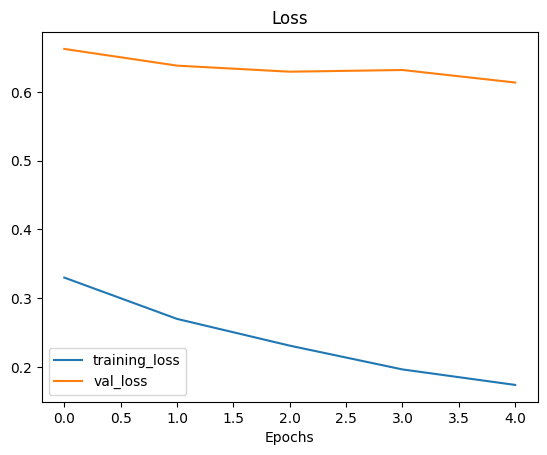

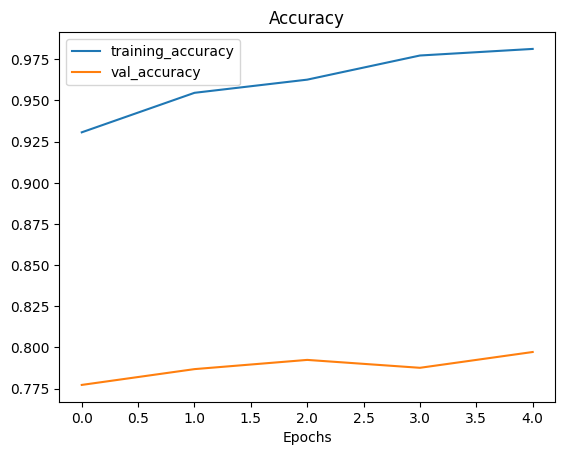

In [ ]:
plot_loss_curves(resnet_history)

In [ ]:
efficientnet_model = create_model(efficientnet_url,
             num_classes = train_data_10_percent.num_classes)

In [ ]:
efficientnet_model.compile(loss="categorical_crossentropy",
                        optimizer=tf.keras.optimizers.Adam(),
                        metrics=["accuracy"])

In [ ]:
efficientnet_history = efficientnet_model.fit(train_data_10_percent,
                       epochs=5,
                       steps_per_epoch=len(train_data_10_percent),
                       validation_data=test_data,
                       validation_steps=len(test_data),
                       verbose=1,
                       callbacks=create_tensorboard_callback(dir_name="tensorflow_hub",
                                                             experiment_name="Efficient-NetB0"))

Saving Tensorboad log files to: tensorflow_hub/Efficient-NetB0/20261029-205533
Epoch 1/5
24/24 [==============================] - 13s 535ms/step - loss: 0.3474 - accuracy: 0.9347 - val_loss: 0.4783 - val_accuracy: 0.8676
Epoch 2/5
24/24 [==============================] - 14s 593ms/step - loss: 0.3122 - accuracy: 0.9440 - val_loss: 0.4620 - val_accuracy: 0.8668
Epoch 3/5
24/24 [==============================] - 13s 559ms/step - loss: 0.2827 - accuracy: 0.9520 - val_loss: 0.4491 - val_accuracy: 0.8724
Epoch 4/5
24/24 [==============================] - 13s 578ms/step - loss: 0.2562 - accuracy: 0.9627 - val_loss: 0.4401 - val_accuracy: 0.8696
Epoch 5/5
24/24 [==============================] - 13s 537ms/step - loss: 0.2336 - accuracy: 0.9680 - val_loss: 0.4292 - val_accuracy: 0.8720


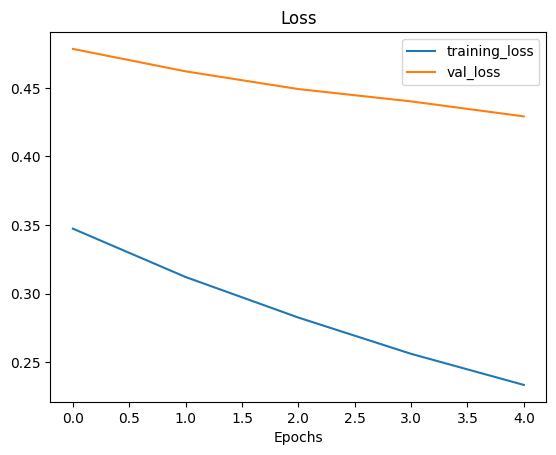

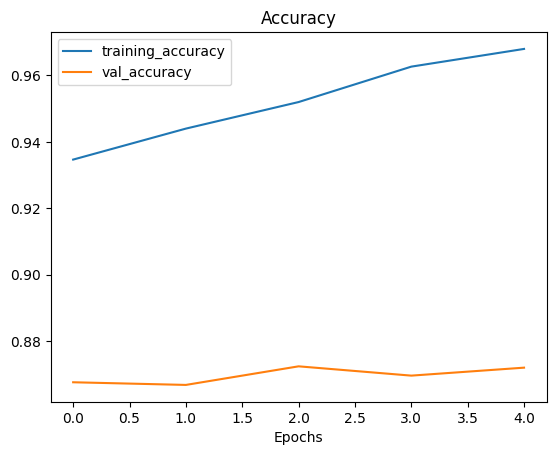

In [ ]:
plot_loss_curves(efficientnet_history)

In [ ]:
efficientnet_model.summary()

Model: "sequential_3"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 feature_extraction_layer (  (None, 1280)              4049564   
 KerasLayer)                                                     
                                                                 
 output_layer (Dense)        (None, 10)                12810     
                                                                 
Total params: 4062374 (15.50 MB)
Trainable params: 12810 (50.04 KB)
Non-trainable params: 4049564 (15.45 MB)
_________________________________________________________________


In [ ]:
len(efficientnet_model.layers[0].weights)

309

## Comparing our model results using TensorBoard